# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in MB
# 1920 * 1080 * 3 channels = 6220800 bytes = 6220800 / (1024**2) MB
frame_mb = (1920 * 1080 * 3) / (1024 ** 2)

# TODO 2: frames per camera per day at 30 fps
# 30 fps * 60 s * 60 m * 24 h
frames_per_day = 30 * 60 * 60 * 24

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
# Total bytes = 400 * frames_per_day * (1920 * 1080 * 3)
# TB = bytes / (1024**4)
fleet_tb = (400 * frames_per_day * (1920 * 1080 * 3)) / (1024 ** 4)

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
fleet_tb_small = (400 * (10 * 60 * 60 * 24) * (640 * 360 * 3)) / (1024 ** 4)
pct_pixels_remaining = ((640 * 360) / (1920 * 1080)) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37 (raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal** piece of evidence the security team could lose forever by making that choice.

_Your answer:_
* **Spatial loss:** Fine structural details like license plate characters, vehicle makes, or facial features become pixelated and unresolvable due to interpolation blur.
* **Temporal loss:** High-speed motion (e.g., a fast-running suspect or a thrown object) is severely undersampled at 10 fps, causing motion aliasing (the correspondence problem) and making it impossible to reconstruct the exact path or timing of the event.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

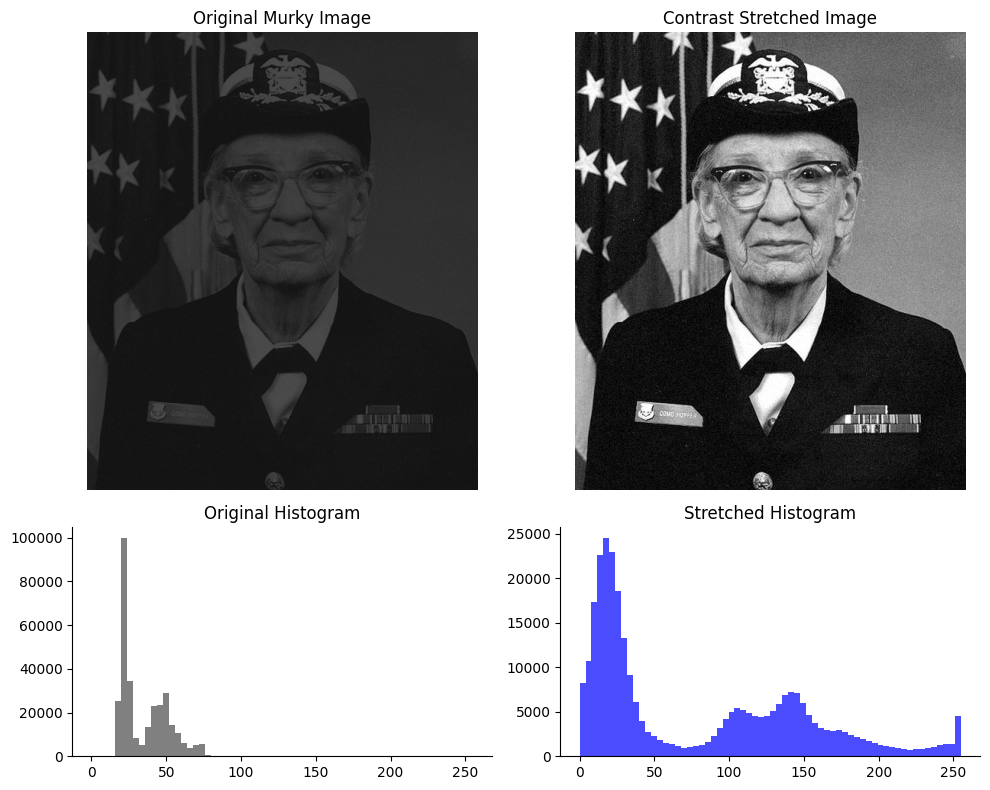

Contrast before: 0.609  ->  after: 1.000


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

p1, p99 = np.percentile(night_still, [1, 99])
c_before = michelson(p99, p1)

# Contrast stretch mapping p1 -> 0 and p99 -> 255
stretched = np.clip((night_still - p1) / (p99 - p1) * 255.0, 0, 255)
sp1, sp99 = np.percentile(stretched, [1, 99])
c_after = michelson(sp99, sp1)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})

# Original Image and Histogram
axes[0, 0].imshow(night_still, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title("Original Murky Image")
axes[0, 0].axis('off')
axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color='gray')
axes[1, 0].set_title("Original Histogram")

# Stretched Image and Histogram
axes[0, 1].imshow(stretched, cmap='gray', vmin=0, vmax=255)
axes[0, 1].set_title("Contrast Stretched Image")
axes[0, 1].axis('off')
axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color='blue', alpha=0.7)
axes[1, 1].set_title("Stretched Histogram")

plt.tight_layout()
plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table). Then explain why stretching made the image readable even though it added **no new information** — and why a histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_
* **Histogram Shape:** The original histogram is extremely **narrow-mid key** or **low-contrast**, clustered tightly around a narrow range of low gray levels with no high-intensity peaks.
* **Readability vs. Information:** Contrast stretching simply remapped existing pixel values to fill the dynamic range (0 to 255). It added no new information but improved human readability by expanding the differences in intensity, making boundaries perceivable to our eyes.
* **Histogram limitation:** A histogram only represents pixel frequency counts but completely ignores spatial arrangement (how pixels are placed next to each other to form shapes and structures). Thus, it cannot describe *what* objects are in the scene.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing (speed < 3 px/s): 68.70-78.10 s
Running (speed > 25 px/s): 78.60-86.00 s


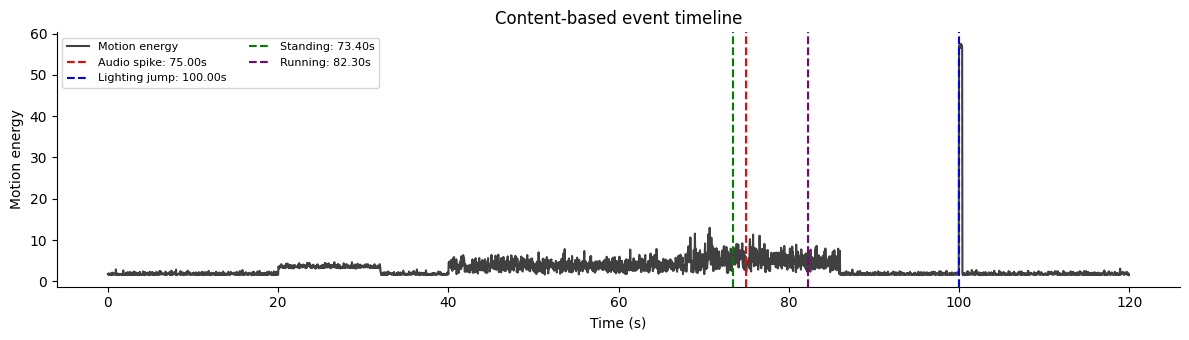

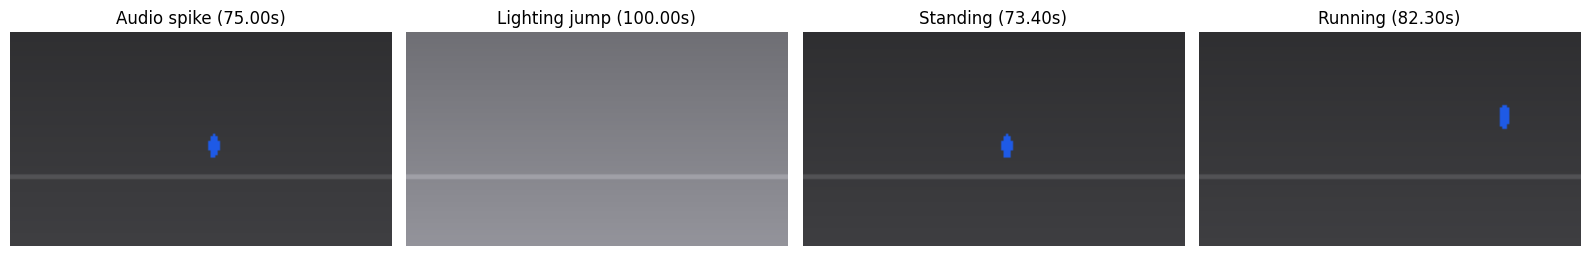

In [4]:
# A 1-second difference reduces jitter compared with a single-frame speed estimate.
dx = cctv['person_x'].diff(FPS)
dy = cctv['person_y'].diff(FPS)
dt = cctv['time_s'].diff(FPS)
speed = np.sqrt(dx**2 + dy**2) / dt
standing_times = cctv.loc[speed < 3, 'time_s']
running_times = cctv.loc[speed > 25, 'time_s']

def describe_range(label, times):
    if times.empty:
        print(f"{label}: not detected")
    else:
        print(f"{label}: {times.min():.2f}-{times.max():.2f} s")

describe_range('Standing (speed < 3 px/s)', standing_times)
describe_range('Running (speed > 25 px/s)', running_times)

audio_events = cctv.index[cctv['audio_level_db'] > -20]
light_events = cctv.index[cctv['mean_brightness'].diff() > 40]
if len(audio_events) == 0 or len(light_events) == 0:
    raise ValueError('Expected an audio and brightness event in the provided log.')
audio_event_idx = audio_events[0]
lighting_event_idx = light_events[0]

# Event-driven timeline, with representative times for all four types of event.
event_indices = {
    'Audio spike': audio_event_idx,
    'Lighting jump': lighting_event_idx,
}
for label, times in [('Standing', standing_times), ('Running', running_times)]:
    if not times.empty:
        t_mid = (times.min() + times.max()) / 2
        event_indices[label] = int((cctv['time_s'] - t_mid).abs().idxmin())

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(cctv['time_s'], cctv['motion_energy'], color='black', alpha=0.75, label='Motion energy')
colors = {'Audio spike':'red', 'Lighting jump':'blue', 'Standing':'green', 'Running':'purple'}
for label, i in event_indices.items():
    ax.axvline(cctv.loc[i, 'time_s'], color=colors[label], linestyle='--', linewidth=1.5,
               label=f"{label}: {cctv.loc[i, 'time_s']:.2f}s")
ax.set(xlabel='Time (s)', ylabel='Motion energy', title='Content-based event timeline')
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(event_indices), figsize=(4 * len(event_indices), 3.3))
for ax, (label, i) in zip(np.atleast_1d(axes), event_indices.items()):
    ax.imshow(render_frame(cctv.iloc[i]))
    ax.set_title(f"{label} ({cctv.loc[i, 'time_s']:.2f}s)")
    ax.axis('off')
plt.tight_layout()
plt.show()


**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_
* **Missed Events:** The lighting event and audio event (which happen abruptly over a split second) would likely be missed because they fall in between the rigid 20-second sampling points.
* **Concept Name:** This event-driven selection approach is called **Content-Based Keyframe Selection** or **Shot-Detection based on motion/audio/brightness features**.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

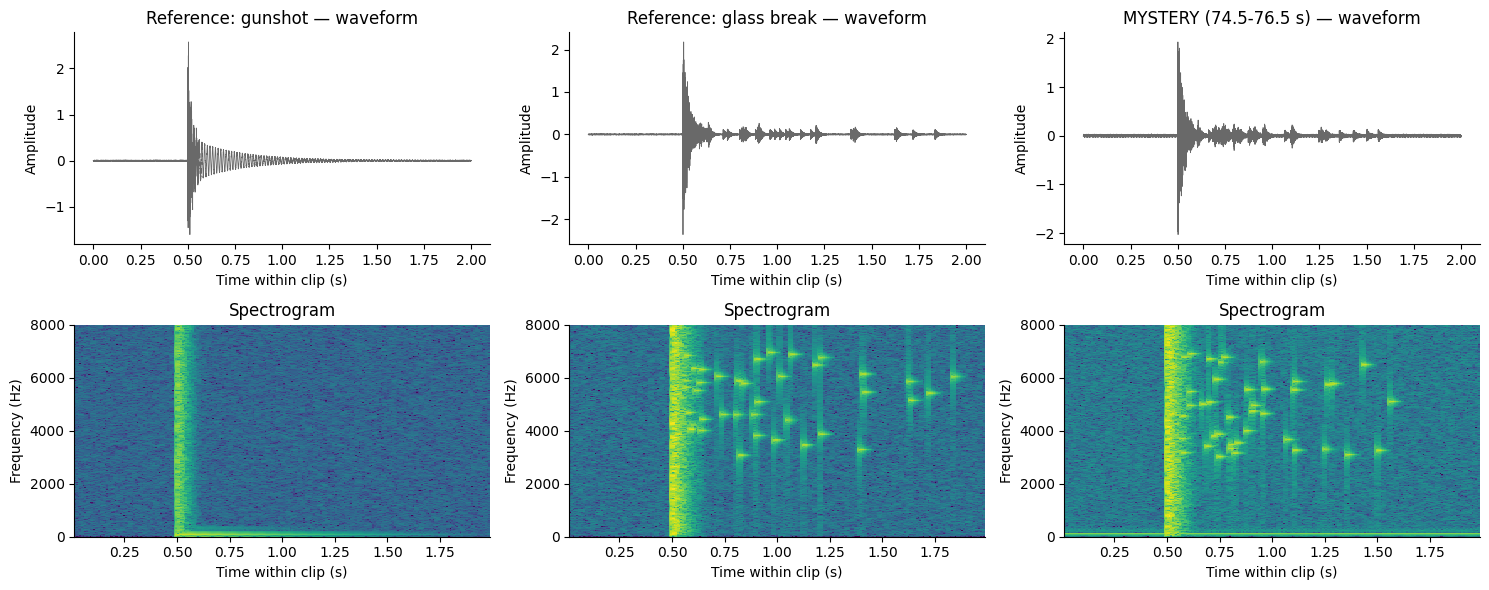

High-frequency (>3 kHz) energy fractions, 0.7-1.7 s within each clip:
  Reference: gunshot: 0.0030
  Reference: glass break: 0.9892
  MYSTERY (74.5-76.5 s): 0.8735
Verdict: GLASS BREAK (closer in this feature to the matching reference; not forensic proof).


In [5]:
# Compare matching 2-second clips: two references and the recording from 74.5 to 76.5 s.
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {
    "Reference: gunshot": ref_gunshot[1],
    "Reference: glass break": ref_glass[1],
    "MYSTERY (74.5-76.5 s)": mystery,
}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
hf_fraction = {}
impact_time = 0.5  # impact begins 0.5 seconds into each two-second clip
window_start, window_end = impact_time + 0.2, impact_time + 1.2

for idx, (name, clip) in enumerate(clips.items()):
    clip_t = np.arange(len(clip)) / FS
    axes[0, idx].plot(clip_t, clip, color='dimgray', linewidth=0.6)
    axes[0, idx].set(title=f"{name} — waveform", xlabel='Time within clip (s)', ylabel='Amplitude')

    freq, times, power = signal.spectrogram(clip, fs=FS, nperseg=512, noverlap=384)
    power_db = 10 * np.log10(np.maximum(power, 1e-12))
    axes[1, idx].pcolormesh(times, freq, power_db, shading='auto', cmap='viridis')
    axes[1, idx].set(title='Spectrogram', xlabel='Time within clip (s)', ylabel='Frequency (Hz)', ylim=(0, 8000))

    # Measure energy between 0.2 and 1.2 seconds AFTER the impact (0.7-1.7 s in clip time).
    relevant_times = (times >= window_start) & (times <= window_end)
    relevant_power = power[:, relevant_times]
    total_power = relevant_power.sum()
    hf_fraction[name] = (relevant_power[freq > 3000].sum() / total_power) if total_power > 0 else np.nan

plt.tight_layout()
plt.show()
print(f"High-frequency (>3 kHz) energy fractions, {window_start:.1f}-{window_end:.1f} s within each clip:")
for name, frac in hf_fraction.items():
    print(f"  {name}: {frac:.4f}")

# Choose the closest of the TWO supplied references, not an arbitrary 10% cutoff.
mystery_frac = hf_fraction["MYSTERY (74.5-76.5 s)"]
if np.isfinite(mystery_frac):
    gunshot_diff = abs(mystery_frac - hf_fraction["Reference: gunshot"])
    glass_diff = abs(mystery_frac - hf_fraction["Reference: glass break"])
    verdict = "GLASS BREAK" if glass_diff < gunshot_diff else "GUNSHOT"
    print(f"Verdict: {verdict} (closer in this feature to the matching reference; not forensic proof).")
else:
    print("Verdict: inconclusive — no usable spectral energy in the comparison window.")


**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern (horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_
* **Waveform limitation:** No, the waveforms look broadly similar because they both show a sudden, loud impact spike that decays over time.
* **Spectrogram Dimensions:** It adds **Time (x-axis)**, **Frequency (y-axis)**, and **Magnitude/Intensity (color/dB scale)**.
* **Decisive Pattern:** The **scattered high-frequency specks** lingering in the higher frequencies (above 3-4 kHz) clearly matched the glass-break pattern, supporting (but not proving) the classification.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

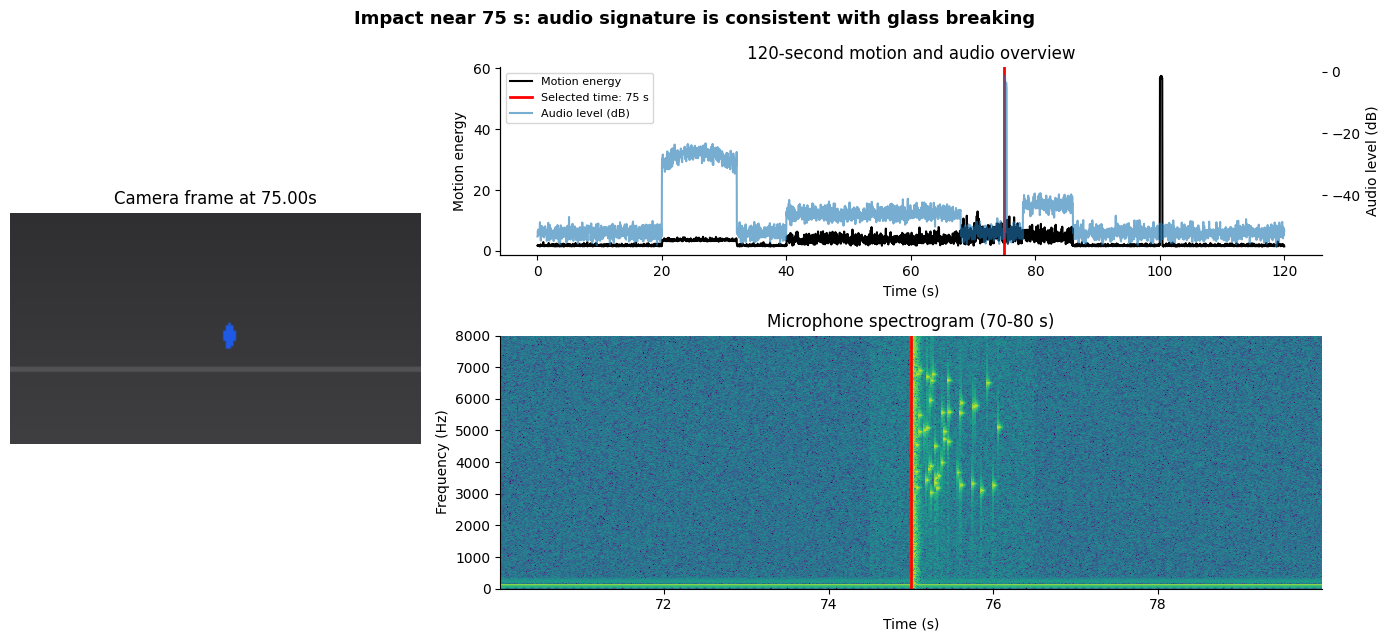

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6.5))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.35])

# Rendered frame closest to the shared time marker.
ax_frame = fig.add_subplot(gs[:, 0])
idx_sel = int((cctv['time_s'] - t_sel).abs().idxmin())
ax_frame.imshow(render_frame(cctv.iloc[idx_sel]))
ax_frame.set_title(f"Camera frame at {cctv.loc[idx_sel, 'time_s']:.2f}s")
ax_frame.axis('off')

# The full 120-second timeline includes BOTH motion and audio levels.
ax_timeline = fig.add_subplot(gs[0, 1])
ax_timeline.plot(cctv['time_s'], cctv['motion_energy'], color='black', label='Motion energy')
ax_audio = ax_timeline.twinx()
ax_audio.plot(cctv['time_s'], cctv['audio_level_db'], color='tab:blue', alpha=0.6,
              label='Audio level (dB)')
ax_timeline.axvline(t_sel, color='red', linewidth=2, label='Selected time: 75 s')
ax_timeline.set(xlabel='Time (s)', ylabel='Motion energy', title='120-second motion and audio overview')
ax_audio.set_ylabel('Audio level (dB)')
lines = ax_timeline.get_lines() + ax_audio.get_lines()
ax_timeline.legend(lines, [line.get_label() for line in lines], fontsize=8, loc='upper left')

# Spectrogram on the same absolute 70-80 second time axis.
ax_spec = fig.add_subplot(gs[1, 1])
freq, t_spec, Sxx = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
ax_spec.pcolormesh(t_audio[0] + t_spec, freq, 10 * np.log10(np.maximum(Sxx, 1e-12)),
                   shading='auto', cmap='viridis')
ax_spec.axvline(t_sel, color='red', linewidth=2)
ax_spec.set(xlabel='Time (s)', ylabel='Frequency (Hz)', ylim=(0, 8000),
            title='Microphone spectrogram (70-80 s)')
fig.suptitle('Impact near 75 s: audio signature is consistent with glass breaking', fontsize=13, weight='bold')
plt.tight_layout()
plt.show()


**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct **synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video? Which panel would make the mistake visible?

_Your answer:_
* **Consequences:** If the audio had a +2s offset, the loud impact sound would appear to occur at 77s while the physical visual motion/light event occurred at 75s, causing a confusing mismatch.
* **Visible Panel:** This mismatch would be instantly visible in the **spectrogram panel**, as the red vertical marker representing the visual event at 75s would no longer align with the acoustic impulse peak.

## Task 6 — The Decision (No Code)

**Briefing Note:**
The synchronized camera and microphone data show a short impact event near 75 seconds in Parking Lot B. The mystery sound has persistent high-frequency components and is **more consistent with the supplied glass-break reference than the gunshot reference**. This is a preliminary classification, not proof that a specific window or bottle broke or that someone committed vandalism. The relevant camera footage and scene should be reviewed before deciding on a response.

The synchronized frame, motion/audio timeline, and spectrogram provide a compact way to review the evidence without losing timing context. For storage, 400 cameras recording uncompressed 1080p RGB at 30 fps would require approximately **5,866 TB/day** (about **5.73 PiB/day**, using 1024-based units); 360p at 10 fps requires approximately **217.3 TB/day**. Downsampling saves about 96.3% of uncompressed storage, but can permanently remove license plate details and fast motion. Retain higher-quality footage around important events rather than relying solely on low-resolution archives.